In [1]:
import pandas as pd
from pandas import DataFrame  as df

#데이터 불러오기 시간이랑 트윗 텍스트만
Data = pd.read_csv("청년층이 많이 대출한 책(전체, CSV).csv")

Data

,검색어,저자,책소개
0,불편한 편의점,김호연,“근데 이게 마지막 술이에요. 이거 먹고 술 끊는 조건으로 우리 가게 일 좀 봐줘요...
1,물고기는 존재하지 않는다,룰루 밀러,‘혼돈’만이 우리의 유일한 지배자라고 아버지는 내게 알려주었다. 혼돈이라는 막무가내...
2,홍학의 자리,정해연,“이 행복이 영원할 거라고 생각한 적은 없었다.\n그러나 이런 끝을 상상한 적도 없...
3,지구 끝의 온실,김초엽,아영은 그렇게 느리고 꾸물거리는 것들이 멀리 퍼져 나가는 과정을 지켜보는 것이 좋았...
4,밝은 밤,최은영,왜 개새끼라고 하나. 개가 사람한테 너무 잘해줘서 그런 거 아닌가. 아무 조건도 없...
...,...,...,...
564,댓글부대,장강명,"“사람들이 두려워하는 걸 건드려야 해. 두려움과 죄의식.\n백만 명, 이백만 명을 ..."
565,고백,김영민,취약함은 인간을 인간이게끔 하는 인간의 특징이다. 인간성을 발견한다는 것은 곧 인간...
566,(굴릴수록 눈덩이처럼 불어나는) 마법의 연금 굴리기,김수한,미래 연금 수령액의 실질 가치는 지금보다 떨어질 가능성이 높습니다. 그러나 실질 가...
567,식빵 유령,윤지,"작은 식빵에 유령이 산다면?\n\n길모퉁이 작은 빵집 안, 식탁 위에 놓인 부숭부숭..."


In [2]:
Data.loc[:, '책소개'] = Data['책소개'].astype(str)

In [5]:
import pandas as pd
import numpy as np

# 데이터 프레임의 'text' 열의 값들을 str 형식으로 바꾸기
Data['책소개'] = Data['책소개'].astype(str)

# 한글이 아니면 빈 문자열로 바꾸기
Data['책소개'] = Data['책소개'].str.replace('[^ㄱ-ㅎㅏ-ㅣ가-힣]', ' ', regex=True)

# 빈 문자열을 NAN 값으로 바꾸기
Data['책소개'] = Data['책소개'].replace({'': np.nan})
Data['책소개'] = Data['책소개'].replace(r'^\s*$', np.nan, regex=True)

# NAN이 있는 행은 삭제
Data.dropna(subset=['책소개'], how='any', inplace=True)

# 인덱스 차곡차곡
Data = Data.reset_index(drop=True)

# 데이터 프레임에 null 값이 있는지 확인
print(Data.isnull().values.any())


False


In [7]:
from konlpy.tag import Okt
import pandas as pd
import numpy as np

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.extend([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 중복 제거
data_word = list(set(data_word))

# 결과를 데이터프레임으로 변환
nouns_df = pd.DataFrame(data_word, columns=['명사'])

# 데이터프레임 출력
print(nouns_df)

         명사
0       평상시
1      절체절명
2       텔레마
3        무도
4        정점
...     ...
13255    스콧
13256   실루엣
13257   램버트
13258    기교
13259    포연

[13260 rows x 1 columns]


In [ ]:
font = 'DoHyeon-Regular.ttf'

In [63]:
import pandas as pd
from konlpy.tag import Okt
import gensim
from gensim.corpora import Dictionary
import re
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.append([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 사전 생성
id2word = Dictionary(data_word)

# 단어 빈도 필터링
id2word.filter_extremes(no_below=5, no_above=0.5)  # 5회 이하로 등장하는 단어와 상위 50% 단어 필터링

# 코퍼스 생성
corpus = [id2word.doc2bow(doc) for doc in data_word]

# LDA 모델 설정
num_topics = 5  # 토픽 개수 설정
lda_model = gensim.models.LdaModel(
    corpus,
    num_topics=num_topics,
    id2word=id2word,
    passes=30,
    random_state=1000,
    alpha='auto',  # alpha 파라미터 자동 설정
    eta='auto'     # eta 파라미터 자동 설정
)

# 결과를 데이터프레임으로 변환
topics = []
for idx, topic in lda_model.show_topics(formatted=False):
    topic_words = sorted(topic, key=lambda x: x[1], reverse=True)  # 비중에 따라 단어 정렬
    topic_words = [word for word, _ in topic_words]  # 단어만 추출
    topics.append((idx, ", ".join(topic_words)))

# 데이터프레임 생성
topics_df = pd.DataFrame(topics, columns=['토픽 번호', '주요 단어'])

# 데이터프레임 출력 
print(topics_df)

# 각 토픽의 상위 n개의 단어 출력
n = 10  # 상위 n개의 단어 수
for idx, topic in lda_model.show_topics(num_topics=num_topics, num_words=n, formatted=False):
    print(f"토픽 {idx + 1}:")
    topic_words = sorted(topic, key=lambda x: x[1], reverse=True)  # 비중에 따라 단어 정렬
    for word, weight in topic_words:
        print(f"{word}: {weight:.4f}")
    print("\n")



   토픽 번호                                     주요 단어
0      0  엄마, 아이, 이야기, 작가, 아기, 마음, 작품, 소설, 사랑, 어린이
1      1    투자, 때문, 주식, 미국, 기업, 시장, 세계, 지금, 수익, 경제
2      2  아이, 엄마, 시간, 친구, 이야기, 마음, 지금, 다른, 아버지, 하나
3      3    사랑, 마음, 그녀, 모든, 그것, 시간, 세상, 하나, 순간, 존재
4      4    당신, 시간, 때문, 인생, 다른, 감정, 사실, 인간, 행동, 가장
토픽 1:
엄마: 0.0197
아이: 0.0171
이야기: 0.0120
작가: 0.0089
아기: 0.0084
마음: 0.0083
작품: 0.0079
소설: 0.0078
사랑: 0.0074
어린이: 0.0073


토픽 2:
투자: 0.0183
때문: 0.0078
주식: 0.0074
미국: 0.0057
기업: 0.0055
시장: 0.0054
세계: 0.0051
지금: 0.0051
수익: 0.0050
경제: 0.0049


토픽 3:
아이: 0.0250
엄마: 0.0143
시간: 0.0093
친구: 0.0091
이야기: 0.0087
마음: 0.0079
지금: 0.0070
다른: 0.0069
아버지: 0.0061
하나: 0.0055


토픽 4:
사랑: 0.0178
마음: 0.0127
그녀: 0.0115
모든: 0.0084
그것: 0.0075
시간: 0.0074
세상: 0.0073
하나: 0.0065
순간: 0.0062
존재: 0.0062


토픽 5:
당신: 0.0164
시간: 0.0131
때문: 0.0099
인생: 0.0088
다른: 0.0080
감정: 0.0080
사실: 0.0078
인간: 0.0074
행동: 0.0073
가장: 0.0068




In [61]:
import pyLDAvis
import pyLDAvis.gensim_models

# pyLDAvis를 사용한 시각화
vis = pyLDAvis.gensim_models.prepare(lda_model, corpus, id2word)
pyLDAvis.display(vis)

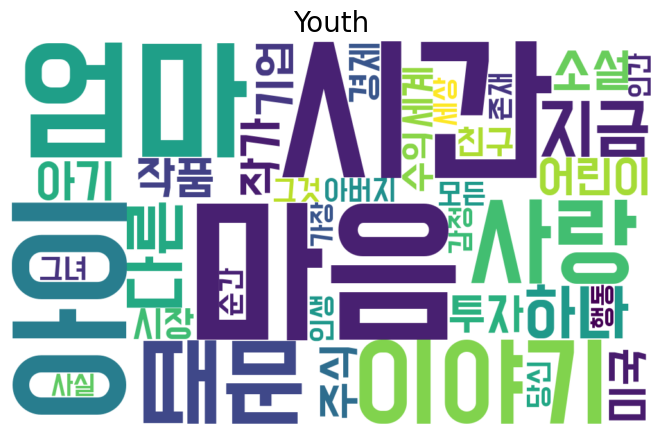

In [62]:
# 워드클라우드 생성
word_string = ", ".join(topics_df['주요 단어'].tolist())

font = 'DoHyeon-Regular.ttf'  # 한글 폰트 경로

wordcloud = WordCloud(
    font_path=font,
    width=1000,
    height=600,
    background_color='white',
    colormap='viridis',
    max_words=200,
    random_state=42
).generate(word_string)

# 워드클라우드 시각화
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Youth', fontsize=20)
plt.show()


<청년>  
토픽 0 : 육아
토픽 1 : 경제
토픽 2 : 가족
토픽 3 : 사랑
토픽 4 : 인생